# Mol chrome progress

Easy → hard ladder for **mol chrome** and the hierarchical **constraint layout** solver.

**Legend:** ✅ working · 🚧 partial · ❌ not yet

| Slice | Constraint layout | Status | Notebook |
|-------|-------------------|--------|----------|
| — | Wire A + Annotation IR B (schema, z bands, paint) | ✅ | below |
| 1 | Tree under `mol/`; Point/Circle/Line/AABB; edge signed-distance | ✅ | `layout_constraints` |
| 2 | Caption kit + simplex; migrate `name=` | ✅ | Ex 1 |
| 3 | Box region text kit; Inside shade/labeled | ✅ | Ex 2–3 |
| 4 | Callout two-point + tip standoff | ✅ | Ex 4 |
| 5 | Atom/map number; outline halo paint-only | ✅ | Ex 5 |
| 6 | Hull proxy; Bezier from proxy; adaptive routes | ✅ | Ex 6+ |

**Restart kernel** after `make agent-install` so the native ext picks up layout changes.


In [1]:
from __future__ import annotations

from xpict import mol
from xpict.contracts.depict import MolNode
from xpict.spec import DepictSpec


def show(smiles: str, *, name: str | dict | None = None, **chrome):
    """Build a lone mol with wire chrome kwargs and display it."""
    plain = name if isinstance(name, str) else None
    base = mol(smiles, name=plain).to_node().model_dump(exclude_none=True)
    if isinstance(name, dict):
        base["name"] = name
    base.update(chrome)
    return DepictSpec(MolNode.model_validate(base))


## Ex 1 · `name=` captions — slice 2 ✅

Privileged caption on the mol (default below). No sibling `TextNode`.

Default font **1.5×** atom labels; chem markup (`$R_1$`); snug to mol AABB via `margin`. Multi-mol rows use HTML `align-items: flex-end`.

Constraint kit (landing): Outside `mol/chem` on preferred side; opt_dist to chem AABB; clash vs bonds+shade; ascent/descent metric box; **simplex** refine after greedy seed.


In [2]:
mol("CCO", name="ethanol") + mol("c1ccccc1O", name="phenol")


DepictSpec(group, 2 mols)

In [3]:
# Markup + custom margin (snug clash pad)
(
    show("CCO", name={"content": "$R_1$OH", "margin": 4})
    + show("c1ccccc1O", name={"content": "Phenol", "margin": 12})
)


DepictSpec(group, 2 mols)

## Ex 2–3 · box region + fill — slice 3 ✅

Box hull around atoms with fill/stroke and inside/outside edge text.

Kit: edge-hug hull; clash vs bonds+shade; Inside shade → hull; Outside/Inside for text.


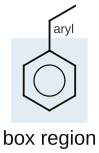

In [4]:
show(
    "c1ccccc1CC",
    name="box region",
    region={
        "style": "box",
        "atoms": [0, 1, 2, 3, 4, 5],
        "fill": {"color": "#48a", "opacity": 0.15},
        "stroke": {"color": "#48a", "width": 1.0},
        "text": {"content": "aryl", "place": "outside", "pos": "above"},
    },
)


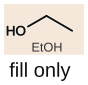

In [5]:
# Fill-only (stroke: null → no outline)
show(
    "CCO",
    name="fill only",
    region={
        "style": "box",
        "atoms": [0, 1, 2],
        "fill": {"color": "#c84", "opacity": 0.2},
        "stroke": None,
        "text": {"content": "EtOH", "place": "inside", "pos": "below"},
    },
)


## Ex 4 · callout (two-point) — slice 4 ✅

Label + tip with tip standoff toward a target atom. No adaptive route points yet (slice 6).

Kit: tip PointStandoff; label Outside chem; clash filters; shared text/arrow color.


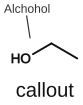

In [6]:
show(
    "CCO",
    name="callout",
    callout={"atoms": [2], "text": "Alchohol", "arrow": True, "prefer": "above"},
)


## Ex 5 · shade + atom numbers / labels — slice 5 ✅

Score wash (house **xenosite** colormap). Numbers may sit on shade with **Halo**. Custom `atom_label` sits beside chem text (does not replace it — use `star_labels` on `*` for that).

Also: `circle` highlights (radius covers atom text).


In [7]:
(
    show("CCO", name="numbers", atom_number="index")
    | show(
        "CCO",
        name="labels",
        atom_label={"0": "Me", "2": "OH"},
    )
    | show(
        "CCO",
        name="shade + #",
        shade={"atoms": [0.1, 0.5, 0.9]},
        atom_number="index",
    )
)


DepictSpec(grid, 3 mols)

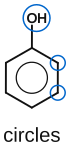

In [8]:
show(
    "c1ccccc1O",
    name="circles",
    circle={"atoms": [0, 1, 6], "stroke": {"color": "#06c", "width": 1.5}},
)


## Ex 6+ · bezier hull / kitchen sink — slice 6 ✅

Hard end of the ladder: curvature-bounded hull proxy for contain/exclude, Bezier paint derived from the solved proxy, adaptive callout route points.

Inside region labels seed like outside on the preferred edge, then **grow** the hull so the label is contained (same rule as circle).


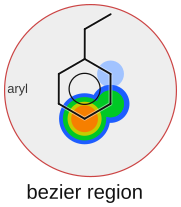

In [9]:
show(
    "c1ccccc1CC",
    name="bezier region",
    shade={"atoms": [0.1, 0.5, 0.9]},
    region={
        "style": "circle",
        "atoms": [0, 1, 2, 3, 4, 5],
        "exclude": [6, 7],
        "fill": {"color": "#eee"},
        "stroke": {"color": "#c44", "width": 1.2},
        "text": {"content": "aryl", "place": "inside", "pos": "left"},
    },
)


## Kitchen sink (stacking / z)

Everything that should compose once paint + constraint slices are complete.


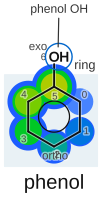

In [10]:
show(
    "c1ccccc1O",
    name="phenol",
    shade={"atoms": [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0]},
    atom_number="index",
    atom_label={"2": "ortho", "6": "exo"},
    circle={"atoms": [6], "stroke": {"color": "#06c", "width": 1.4}},
    region={
        "style": "box",
        "atoms": [0, 1, 2, 3, 4, 5],
        "fill": {"color": "#48a", "opacity": 0.12},
        "stroke": {"color": "#48a", "width": 1.0},
        "text": "ring",
    },
    callout={"atoms": [6], "text": "phenol OH", "arrow": True, "prefer": "above"},
)
